In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C7"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C7_10,28,"[DATA/TRAINING/C7/C7_10/IMG_8189.HEIC, DATA/TR..."
1,C7_11,27,"[DATA/TRAINING/C7/C7_11/IMG_8248.HEIC, DATA/TR..."
2,C7_12,25,"[DATA/TRAINING/C7/C7_12/IMG_8280.HEIC, DATA/TR..."
3,C7_13,25,"[DATA/TRAINING/C7/C7_13/IMG_8311.HEIC, DATA/TR..."
4,C7_14,25,"[DATA/TRAINING/C7/C7_14/IMG_8406.HEIC, DATA/TR..."
5,C7_15,25,"[DATA/TRAINING/C7/C7_15/IMG_8343.HEIC, DATA/TR..."
6,C7_16,27,"[DATA/TRAINING/C7/C7_16/IMG_8375.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8189.HEIC')

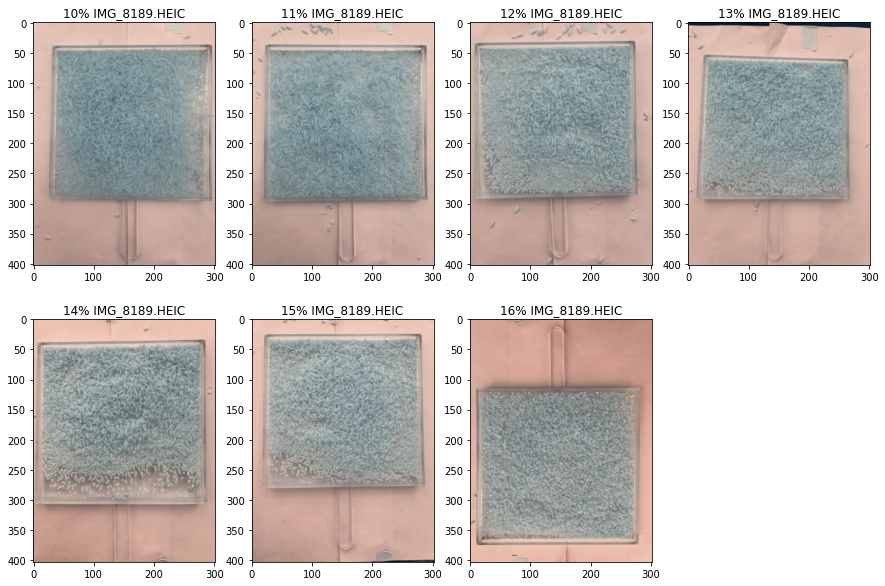

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.055360,0.046023,0.025169,0.020726,0.018511,0.023014,0.026783,0.041440,0.050631,0.041778,...,0.086384,0.372177,25,16,2,1008,756,3,IMG_8189.HEIC,10
1,0.055571,0.045725,0.025592,0.020054,0.018668,0.023705,0.027926,0.042945,0.053111,0.042970,...,0.082131,0.370160,25,16,2,1008,756,3,IMG_8190.HEIC,10
2,0.056368,0.045896,0.025428,0.021238,0.019437,0.024193,0.028017,0.041971,0.051408,0.040980,...,0.083352,0.371002,25,16,2,1008,756,3,IMG_8193.HEIC,10
3,0.055506,0.045363,0.026244,0.021093,0.019387,0.024197,0.028519,0.043653,0.053889,0.042370,...,0.080263,0.365949,25,16,2,1008,756,3,IMG_8194.HEIC,10
4,0.052473,0.044220,0.025002,0.021197,0.019026,0.024443,0.029116,0.045357,0.055267,0.044900,...,0.083383,0.358603,25,16,2,1008,756,3,IMG_8199.HEIC,10
5,0.054124,0.044395,0.025897,0.021300,0.020289,0.025641,0.029368,0.044522,0.053976,0.042157,...,0.080541,0.364591,25,16,2,1008,756,3,IMG_8206.HEIC,10
6,0.054182,0.044313,0.026046,0.021692,0.020193,0.026191,0.030410,0.045224,0.055393,0.042917,...,0.078779,0.361931,25,16,2,1008,756,3,IMG_8210.HEIC,10
7,0.049475,0.041828,0.025775,0.022604,0.021384,0.027624,0.033603,0.052404,0.065517,0.050254,...,0.074973,0.333726,25,16,2,1008,756,3,IMG_8211.HEIC,10
8,0.053268,0.044222,0.025787,0.021340,0.020344,0.025611,0.030740,0.048704,0.061866,0.045556,...,0.075002,0.354790,25,16,2,1008,756,3,IMG_8215.HEIC,10
9,0.050532,0.042542,0.024971,0.021953,0.020711,0.026917,0.032138,0.050040,0.063121,0.048749,...,0.076107,0.343688,25,16,2,1008,756,3,IMG_8216.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.789474,0.809524,0.785714,0.797441,LBP,C7,RF_C,25,16,2,1008,756,3
1,2,0.526316,0.571429,0.523810,0.546584,LBP,C7,RF_C,25,16,2,1008,756,3
2,3,0.388889,0.547619,0.428571,0.480836,LBP,C7,RF_C,25,16,2,1008,756,3
3,4,0.666667,0.726190,0.666667,0.695157,LBP,C7,RF_C,25,16,2,1008,756,3
4,5,0.444444,0.523810,0.452381,0.485482,LBP,C7,RF_C,25,16,2,1008,756,3
5,6,0.611111,0.559524,0.595238,0.576829,LBP,C7,RF_C,25,16,2,1008,756,3
6,7,0.666667,0.690476,0.642857,0.665816,LBP,C7,RF_C,25,16,2,1008,756,3
7,8,0.777778,0.833333,0.809524,0.821256,LBP,C7,RF_C,25,16,2,1008,756,3
8,9,0.777778,0.785714,0.785714,0.785714,LBP,C7,RF_C,25,16,2,1008,756,3
9,10,0.888889,0.916667,0.880952,0.898455,LBP,C7,RF_C,25,16,2,1008,756,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C7,RF_C,0.653801,0.657143,0.675357,0.696429


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.789474,0.859524,0.761905,0.807776,LBP,C7,MLP_C,25,16,2,1008,756,3
1,2,0.947368,0.964286,0.952381,0.958296,LBP,C7,MLP_C,25,16,2,1008,756,3
2,3,0.833333,0.892857,0.857143,0.874636,LBP,C7,MLP_C,25,16,2,1008,756,3
3,4,0.666667,0.690476,0.690476,0.690476,LBP,C7,MLP_C,25,16,2,1008,756,3
4,5,0.611111,0.678571,0.619048,0.647444,LBP,C7,MLP_C,25,16,2,1008,756,3
5,6,0.777778,0.857143,0.761905,0.806723,LBP,C7,MLP_C,25,16,2,1008,756,3
6,7,0.722222,0.785714,0.690476,0.735023,LBP,C7,MLP_C,25,16,2,1008,756,3
7,8,0.722222,0.714286,0.714286,0.714286,LBP,C7,MLP_C,25,16,2,1008,756,3
8,9,0.500000,0.500000,0.476190,0.487805,LBP,C7,MLP_C,25,16,2,1008,756,3
9,10,0.611111,0.692857,0.619048,0.653876,LBP,C7,MLP_C,25,16,2,1008,756,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C7,MLP_C,0.718129,0.714286,0.737634,0.763571


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.473684,0.595238,0.476190,0.529101,LBP,C7,XGB_C,25,16,2,1008,756,3
1,2,0.578947,0.633333,0.571429,0.600791,LBP,C7,XGB_C,25,16,2,1008,756,3
2,3,0.444444,0.592857,0.500000,0.542484,LBP,C7,XGB_C,25,16,2,1008,756,3
3,4,0.666667,0.704762,0.690476,0.697546,LBP,C7,XGB_C,25,16,2,1008,756,3
4,5,0.722222,0.773810,0.714286,0.742857,LBP,C7,XGB_C,25,16,2,1008,756,3
5,6,0.722222,0.761905,0.738095,0.749811,LBP,C7,XGB_C,25,16,2,1008,756,3
6,7,0.500000,0.511905,0.523810,0.517789,LBP,C7,XGB_C,25,16,2,1008,756,3
7,8,0.555556,0.500000,0.523810,0.511628,LBP,C7,XGB_C,25,16,2,1008,756,3
8,9,0.666667,0.723810,0.642857,0.680936,LBP,C7,XGB_C,25,16,2,1008,756,3
9,10,0.777778,0.797619,0.761905,0.779353,LBP,C7,XGB_C,25,16,2,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C7,XGB_C,0.610819,0.614286,0.635229,0.659524


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C7_10,5,"[DATA/TEST/C7/C7_10/IMG_8188.HEIC, DATA/TEST/C..."
1,C7_11,5,"[DATA/TEST/C7/C7_11/IMG_8249.HEIC, DATA/TEST/C..."
2,C7_12,5,"[DATA/TEST/C7/C7_12/IMG_8279.HEIC, DATA/TEST/C..."
3,C7_13,5,"[DATA/TEST/C7/C7_13/IMG_8316.HEIC, DATA/TEST/C..."
4,C7_14,5,"[DATA/TEST/C7/C7_14/IMG_8411.HEIC, DATA/TEST/C..."
5,C7_15,5,"[DATA/TEST/C7/C7_15/IMG_8344.HEIC, DATA/TEST/C..."
6,C7_16,5,"[DATA/TEST/C7/C7_16/IMG_8377.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.054354,0.045098,0.025459,0.020864,0.018843,0.023396,0.027378,0.042155,0.051951,0.042253,...,0.085928,0.368378,25,16,2,1008,756,3,IMG_8188.HEIC,10
1,0.055747,0.046769,0.025392,0.019945,0.017982,0.022373,0.026564,0.041875,0.053396,0.040673,...,0.083663,0.373337,25,16,2,1008,756,3,IMG_8198.HEIC,10
2,0.056389,0.046493,0.025841,0.020677,0.019255,0.023785,0.027779,0.042559,0.052750,0.041193,...,0.080171,0.374375,25,16,2,1008,756,3,IMG_8202.HEIC,10
3,0.052808,0.043311,0.025784,0.022021,0.020856,0.026521,0.031350,0.047804,0.056464,0.043943,...,0.079587,0.354360,25,16,2,1008,756,3,IMG_8203.HEIC,10
4,0.055902,0.046208,0.025973,0.021224,0.019427,0.024149,0.028023,0.042028,0.050175,0.039768,...,0.083324,0.373062,25,16,2,1008,756,3,IMG_8207.HEIC,10
0,0.055867,0.046740,0.024525,0.019967,0.018079,0.022694,0.027061,0.041003,0.050345,0.042007,...,0.082881,0.378330,25,16,2,1008,756,3,IMG_8249.HEIC,11
1,0.056323,0.046067,0.025109,0.020639,0.018849,0.023426,0.027505,0.042470,0.051709,0.042504,...,0.081504,0.373787,25,16,2,1008,756,3,IMG_8251.HEIC,11
2,0.057100,0.045669,0.025414,0.020285,0.018895,0.023425,0.027984,0.042583,0.051692,0.042331,...,0.081845,0.370979,25,16,2,1008,756,3,IMG_8252.HEIC,11
3,0.054536,0.043749,0.026985,0.022960,0.021079,0.025687,0.030392,0.046014,0.056126,0.045163,...,0.077713,0.353196,25,16,2,1008,756,3,IMG_8264.HEIC,11
4,0.057139,0.045464,0.026151,0.021333,0.019375,0.023366,0.027816,0.042462,0.052667,0.043045,...,0.079260,0.371600,25,16,2,1008,756,3,IMG_8272.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.67      0.80      0.73         5
     Class 1       0.40      0.40      0.40         5
     Class 2       1.00      0.40      0.57         5
     Class 3       0.71      1.00      0.83         5
     Class 4       0.80      0.80      0.80         5
     Class 5       0.33      0.40      0.36         5
     Class 6       0.50      0.40      0.44         5

    accuracy                           0.60        35
   macro avg       0.63      0.60      0.59        35
weighted avg       0.63      0.60      0.59        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      1.00      1.00         5
     Class 4       1.00      0.80      0.89         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.89        35
   macro avg       0.89      0.89      0.89        35
weighted avg       0.89      0.89      0.89        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.83      1.00      0.91         5
     Class 1       0.60      0.60      0.60         5
     Class 2       0.50      0.40      0.44         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.43      0.60      0.50         5
     Class 6       0.60      0.60      0.60         5

    accuracy                           0.57        35
   macro avg       0.57      0.57      0.56        35
weighted avg       0.57      0.57      0.56        35

